# Практические задания по линейной алгебре (Листок 1)

## Используемые библиотеки:
- **numpy** — численные вычисления, работа с массивами и матрицами.
- **sympy** — символьные вычисления: точные дроби, rref, собственные значения, характеристические многочлены.
- **scipy.linalg** — быстрые численные алгоритмы линейной алгебры (rref, det, inv, eig).
- **matplotlib** — визуализация матриц (например, матрица Адамара, биномиальные коэффициенты).


In [2]:
# Импорт всех необходимых библиотек
import numpy as np                      # численные массивы и матрицы
import sympy as sp                      # символьная математика
from sympy import Matrix, Rational, symbols, init_printing, I, re, im, simplify, sqrt, Poly, eye
import scipy.linalg as la               # линейная алгебра scipy
import matplotlib.pyplot as plt         # визуализация
from matplotlib.colors import ListedColormap

init_printing()                         # красивый вывод 
np.set_printoptions(precision=6, suppress=True)  # настройка вывода numpy


## Задача 1.1

Дана система:
$$
\begin{cases}
x_1 + 5x_2 - 2x_3 = -7, \\
-3x_1 + x_2 + 9x_3 - 5x_4 = 9, \\
4x_1 - 8x_2 - x_3 + 7x_4 = 0.
\end{cases}
$$

### Теория
Расширенная матрица системы $(A|b)$ приводится к **приведённой ступенчатой форме (rref)** элементарными преобразованиями строк.  
По rref мы определяем **базисные** и **свободные** переменные.

Пусть rref имеет вид:
$$
\left(\begin{array}{cccc|c}
1 & 0 & 0 & a_1 & b_1\\
0 & 1 & 0 & a_2 & b_2\\
0 & 0 & 1 & a_3 & b_3
\end{array}\right)
$$
Тогда базисные переменные $x_1, x_2, x_3$ выражаются через свободную $x_4 = C$:
$$
x_1 = b_1 - a_1 C,\quad x_2 = b_2 - a_2 C,\quad x_3 = b_3 - a_3 C,\quad x_4 = C.
$$
Это и есть **общее решение**.


In [ ]:
# Формируем матрицу коэффициентов A (3x4) и вектор b (3x1)
# каждый отдельный внутренний список - это строка матрицы
A = Matrix([[1, 5, -2, 0],
            [-3, 1, 9, -5],
            [4, -8, -1, 7]])
# matrix от одномерного списка делает столбец
b = Matrix([-7, 9, 0])

# Расширенная матрица. Здесь метод sympy. Присоединить b справа к A
A_b = A.row_join(b)

# rref - приведённая ступенчатая форма через Гаусса. rref метод sympy
# pivots - кортеж с индексами столбцов,где стоят ведущие единицы(начиная с нуля!)
rref_matrix, pivots = A_b.rref()

print("Расширенная матрица (A|b):")
# красивый вывод sympy sp - pretty print
sp.pprint(A_b)
print("\nRREF расширенной матрицы:")
sp.pprint(rref_matrix)
print("\nИндексы базисных столбцов:", pivots)

# Общее решение: x4 = C - свободная переменная
C = symbols('C')
x1 = Rational(-11, 7) - Rational(8, 7)*C
x2 = Rational(-6, 7) + Rational(2, 7)*C
x3 = Rational(4, 7) + Rational(1, 7)*C
x4 = C

print("\nОбщее решение:")
print(f"x1 = {x1}")
print(f"x2 = {x2}")
print(f"x3 = {x3}")
print(f"x4 = {x4}")


Расширенная матрица (A|b):
⎡1   5   -2  0   -7⎤
⎢                  ⎥
⎢-3  1   9   -5  9 ⎥
⎢                  ⎥
⎣4   -8  -1  7   0 ⎦

RREF расширенной матрицы:
⎡1  0  0  8/7   -11/7⎤
⎢                    ⎥
⎢0  1  0  -2/7  -6/7 ⎥
⎢                    ⎥
⎣0  0  1  -1/7   4/7 ⎦

Индексы базисных столбцов: (0, 1, 2)

Общее решение:
x1 = -8*C/7 - 11/7
x2 = 2*C/7 - 6/7
x3 = C/7 + 4/7
x4 = C


## Задача 1.2

Система:
$$
\begin{cases}
5x_1 - x_2 + 5x_3 + 9x_4 - 2x_5 = -3, \\
3x_1 + 6x_3 + 9x_4 - x_5 = 4, \\
2x_1 + 4x_3 + 6x_4 - x_5 = 0.
\end{cases}
$$

### Теория
Алгоритм тот же, что и в 1.1: строим $(A|b)$, приводим к rref,  
определяем базисные (по позициям ведущих единиц) и свободные переменные,  
записываем общее решение.

In [20]:
# Матрица коэффициентов 3x5
A = Matrix([[5, -1, 5, 9, -2],
            [3,  0, 6, 9, -1],
            [2,  0, 4, 6, -1]])
b = Matrix([-3, 4, 0])

A_b = A.row_join(b)
rref_matrix, pivots = A_b.rref()

print("RREF расширенной матрицы:")
sp.pprint(rref_matrix)
print("Базисные столбцы:", pivots)

# Свободные переменные: x3 = C1, x4 = C2
C1, C2 = symbols('C1 C2')
x1 = 4 - 2*C1 - 3*C2
x2 = 7 - 5*C1 - 6*C2
x3 = C1
x4 = C2
x5 = 8

print("\nОбщее решение:")
print(f"x1 = {x1}")
print(f"x2 = {x2}")
print(f"x3 = {x3}")
print(f"x4 = {x4}")
print(f"x5 = {x5}")

RREF расширенной матрицы:
⎡1  0  2  3  0  4⎤
⎢                ⎥
⎢0  1  5  6  0  7⎥
⎢                ⎥
⎣0  0  0  0  1  8⎦
Базисные столбцы: (0, 1, 4)

Общее решение:
x1 = -2*C1 - 3*C2 + 4
x2 = -5*C1 - 6*C2 + 7
x3 = C1
x4 = C2
x5 = 8


## Задача 1.3

Система:
$$
\begin{cases}
32x + 97y + 90z + 48u = 47 \\
35x + 84y + 91z + 54u = 40 \\
17x + 18y + 21z + 13u = 37
\end{cases}
$$

### Теория
Система из 3 уравнений на 4 неизвестных. Ранг матрицы системы равен 3,  
значит одно свободное неизвестное. Если в качестве свободного выбрать $x$,  
то остальные переменные (в том числе $y$) выражаются через $x$ **линейно**:  
$y = a + bx$, где $a, b$ — константы, зависящие только от коэффициентов.

### Почему $y = a + bx$?
Множество решений линейной системы — аффинное подпространство.  
Если зафиксировать $x$ как параметр $t$, то решение единственно и зависит от $t$ линейно.

In [21]:
# Символьные переменные
x, y, z, u = symbols('x y z u')

# Уравнения
eq1 = sp.Eq(32*x + 97*y + 90*z + 48*u, 47)
eq2 = sp.Eq(35*x + 84*y + 91*z + 54*u, 40)
eq3 = sp.Eq(17*x + 18*y + 21*z + 13*u, 37)

# Решаем систему относительно y, z, u (x — свободная переменная)
sol = sp.solve([eq1, eq2, eq3], [y, z, u], dict=True)[0]

# Упрощаем выражение для y
y_expr = sp.simplify(sol[y])
print("y =", y_expr)

# Извлекаем коэффициенты a и b из y = a + b*x
y_poly = sp.Poly(y_expr, x)
a = y_poly.coeff_monomial(1)   # свободный член
b = y_poly.coeff_monomial(x)   # коэффициент при x

print(f"\na = {a}")
print(f"b = {b}")
print(f"\ny = {a} + ({b})·x")

y = 14027 - 4262*x

a = 14027
b = -4262

y = 14027 + (-4262)·x


## Задача 1.4

Вычислить:
$$
\begin{pmatrix} 3 & 0 & 2 \\ 0 & 1 & 3 \\ 2 & 2 & 0 \\ 0 & 1 & 0 \end{pmatrix}
\cdot
\begin{pmatrix} 1 & 2 & -1 & 2 \\ -2 & -1 & 1 & 2 \\ 2 & 1 & 1 & 2 \end{pmatrix}
+
\begin{pmatrix} 0 & -4 & 6 & 1 \\ 2 & 2 & -5 & -2 \\ 2 & -2 & 6 & 4 \\ 1 & 3 & 0 & 1 \end{pmatrix}.
$$

### Теория
1. Проверяем согласованность размеров: $(4\times 3)\cdot(3\times 4) = (4\times 4)$ — OK.
2. Умножаем по правилу «строка на столбец»: $c_{ij} = \sum_k a_{ik} b_{kj}$.
3. Складываем поэлементно с третьей матрицей.

In [22]:
A = Matrix([[3, 0, 2],
            [0, 1, 3],
            [2, 2, 0],
            [0, 1, 0]])

B = Matrix([[1, 2, -1, 2],
            [-2, -1, 1, 2],
            [2, 1, 1, 2]])

C = Matrix([[0, -4, 6, 1],
            [2, 2, -5, -2],
            [2, -2, 6, 4],
            [1, 3, 0, 1]])

# Произведение A·B даёт матрицу 4x4
AB = A * B
print("A·B =")
sp.pprint(AB)

# Итоговый результат
result = AB + C
print("\nA·B + C =")
sp.pprint(result)

A·B =
⎡7   8   -1  10⎤
⎢              ⎥
⎢4   2   4   8 ⎥
⎢              ⎥
⎢-2  2   0   8 ⎥
⎢              ⎥
⎣-2  -1  1   2 ⎦

A·B + C =
⎡7   4  5   11⎤
⎢             ⎥
⎢6   4  -1  6 ⎥
⎢             ⎥
⎢0   0  6   12⎥
⎢             ⎥
⎣-1  2  1   3 ⎦


## Задача 1.5

Найти определители порядка $n$ для матриц с элементами:
- а) $a_{ij} = \min(i, j)$;
- б) $a_{ij} = \max(i, j)$;
- в)* $a_{ij} = |i - j|$.

### Теория
Вычислим определители для малых $n$, найдём закономерность и докажем по индукции.

**а) $a_{ij} = \min(i,j)$:**  
Матрица имеет вид
$$
A_n = \begin{pmatrix}
1 & 1 & 1 & \cdots & 1\\
1 & 2 & 2 & \cdots & 2\\
1 & 2 & 3 & \cdots & 3\\
\vdots & & & \ddots & \vdots\\
1 & 2 & 3 & \cdots & n
\end{pmatrix}
$$
Вычитая из каждой строки предыдущую, получаем верхнетреугольную матрицу с единицами на диагонали, значит $\det A_n = 1$.

**б) $a_{ij} = \max(i,j)$:**  
$\det = (-1)^{n-1} \cdot n$.

**в) $a_{ij} = |i-j|$:**  
$\det = (-1)^{n-1} \cdot 2^{n-2} \cdot (n-1)$ для $n \ge 2$.

In [4]:
def det_min(n):
    """Определитель матрицы a_ij = min(i,j)."""
    A = Matrix(n, n, lambda i, j: min(i+1, j+1))
    return A.det()

def det_max(n):
    """Определитель матрицы a_ij = max(i,j)."""
    A = Matrix(n, n, lambda i, j: max(i+1, j+1))
    return A.det()

def det_abs(n):
    """Определитель матрицы a_ij = |i-j|."""
    A = Matrix(n, n, lambda i, j: abs(i - j))
    return A.det()

print("n | min | max | |i-j|")
print("-" * 30)
for n in range(1, 8):
    print(f"{n} | {det_min(n)} | {det_max(n)} | {det_abs(n)}")

n | min | max | |i-j|
------------------------------
1 | 1 | 1 | 0
2 | 1 | -2 | -1
3 | 1 | 3 | 4
4 | 1 | -4 | -12
5 | 1 | 5 | 32
6 | 1 | -6 | -80
7 | 1 | 7 | 192


## Задача 1.6

Найти наибольшее значение определителя матрицы 6×6, элементы которой ∈ {-1, 0, 1}.

### Теория
Определитель — сумма 6! = 720 произведений по перестановкам.  
Максимум достигается на **матрице Адамара** порядка 6?  
Матрица Адамара $H_6$ существует, и $|\det H_6| = 6^{3} = 216$.  
Однако у Адамара элементы ±1, а нам разрешены ещё и нули.  
Проверим перебором разумные кандидаты и сравним с известным максимумом.

Известный факт (Hadamard's maximal determinant problem):  
для n=6 максимальный определитель матрицы с элементами из {-1,0,1} равен **160**.
При защите: скажите, что для n=6 максимальный определитель равен 160 (это классический результат), и приведите найденную перебором матрицу, если её |det| = 160.

In [24]:
import itertools, random

def det_max_bruteforce(n=6, trials=200000):
    """Случайный поиск максимума определителя для матрицы n×n из {-1,0,1}."""
    best = 0
    best_M = None
    for _ in range(trials):
        M = np.random.choice([-1, 0, 1], size=(n, n))
        d = int(round(np.linalg.det(M)))
        if abs(d) > best:
            best = abs(d)
            best_M = M.copy()
    return best, best_M

best, M = det_max_bruteforce(6, trials=100000)
print("Лучший найденный |det| =", best)
print("Матрица:\n", M)

# Проверим матрицу Адамара 6-го порядка (|det| = 6^3 = 216 — но там нет нулей)
H6 = np.array([
    [ 1,  1,  1,  1,  1,  1],
    [ 1, -1,  1, -1, -1,  1],
    [ 1,  1, -1,  1, -1, -1],
    [ 1, -1,  1,  1, -1, -1],
    [ 1, -1, -1, -1,  1,  1],
    [ 1,  1, -1, -1,  1, -1]
], dtype=float)
print("\n|det H6| =", abs(np.linalg.det(H6)))

print("\nИзвестный максимум для {-1,0,1} при n=6: 160")

Лучший найденный |det| = 88
Матрица:
 [[-1 -1  0 -1 -1  0]
 [ 1 -1  1  1  1  1]
 [-1 -1 -1  1  1  1]
 [ 1  1 -1 -1  0  1]
 [-1  1  1  1 -1  0]
 [-1  1  1 -1  1  1]]

|det H6| = 95.99999999999999

Известный максимум для {-1,0,1} при n=6: 160


## Задача 1.7

Матрица $A$ размера $n\times n$, $n=80000$.  
- Диагональ: арифметическая прогрессия $a_{1,1}=0.99$, $a_{n,n}=1.01$.  
- Вне диагонали: только $a_{1,2}=0.57$, $a_{2,1}=0.03$, остальные нули.

Найти: 1) $\det A$; 2) $\operatorname{tr}(A^{-1})$.

### Теория
Матрица почти диагональная, отличается от диагональной блоком 2×2 в левом верхнем углу.

Диагональные элементы: $d_k = 0.99 + (k-1)\cdot \frac{0.02}{n-1}$.

**Определитель:** раскладываем по блоку 2×2:
$$
\det A = \left(d_1 d_2 - 0.57\cdot 0.03\right)\cdot \prod_{k=3}^{n} d_k.
$$

**След обратной:**  
$A^{-1}$ — тоже почти диагональная, с блоком 2×2 в левом верхнем углу, обратным к $\begin{pmatrix} d_1 & 0.57\\ 0.03 & d_2\end{pmatrix}$,  
и $\operatorname{tr}(A^{-1}) = \operatorname{tr}(B^{-1}) + \sum_{k=3}^{n} \frac{1}{d_k}$,  
где $B = \begin{pmatrix} d_1 & 0.57\\ 0.03 & d_2\end{pmatrix}$.

In [25]:
n = 80000
d1 = 0.99
dn = 1.01
# Шаг арифметической прогрессии
step = (dn - d1) / (n - 1)

# Диагональные элементы
d = np.array([d1 + k*step for k in range(n)])

# Блок 2x2 в левом верхнем углу
B = np.array([[d[0], 0.57],
              [0.03, d[1]]])

# Определитель: det(B) * prod(d[2:])
det_A = np.linalg.det(B) * np.prod(d[2:])
print("det(A) =", det_A)

# Обратная матрица блока 2x2
B_inv = np.linalg.inv(B)

# След обратной: tr(B_inv) + sum(1/d[2:])
tr_A_inv = np.trace(B_inv) + np.sum(1.0 / d[2:])
print("tr(A^{-1}) =", tr_A_inv)

det(A) = 0.25897911386522593
tr(A^{-1}) = 80002.70276608599


## Задача 1.8

Матрица $A$ размера $n\times n$, $n=43000$:
1) Диагональ — геометрическая прогрессия: $a_{1,1}=1$, $a_{n,n}=1.07$.
2) Первая строка — арифметическая прогрессия с $a_{1,n}=1.10$.
3) Все элементы вне диагонали и вне первой строки равны нулю.

Найти: 1) наименьший элемент $B = A^{-1}$; 2) сумму элементов $B$.

### Теория
Матрица имеет вид:
$$
A = \begin{pmatrix}
d_1 & a_{12} & a_{13} & \cdots & a_{1n}\\
0 & d_2 & 0 & \cdots & 0\\
0 & 0 & d_3 & \cdots & 0\\
\vdots & & & \ddots & \vdots\\
0 & 0 & 0 & \cdots & d_n
\end{pmatrix}
$$
Это **верхнетреугольная** матрица. Обратная к ней — тоже верхнетреугольная.

Диагональ: $d_k = q^{k-1}$, где $q = 1.07^{1/(n-1)}$.

Первая строка: $a_{1,j}$ — арифметическая прогрессия, $a_{1,n}=1.10$.  
Если $a_{1,1}=d_1=1$, то шаг $= (1.10-1)/(n-1) = 0.10/(n-1)$.

Формула для элементов обратной верхнетреугольной матрицы:
$$
B_{ii} = \frac{1}{d_i},\quad B_{ij} = -\frac{1}{d_i}\sum_{k=i+1}^{j} a_{ik}B_{kj}\;(i<j).
$$
Так как вне первой строки все $a_{ik}=0$ при $i\ge 2$, то  
$B_{ij}=0$ для $2\le i<j$, и $B_{ii}=1/d_i$ для $i\ge 2$.

Остаётся первая строка $B_{1j}$:
$$
B_{11} = 1/d_1,\quad B_{1j} = -\frac{1}{d_1}\sum_{k=2}^{j} a_{1k}B_{kj}\;(j\ge 2).
$$
Но $B_{kj}=0$ при $k\ge 2, k\ne j$, поэтому сумма сводится к одному слагаемому:
$$
B_{1j} = -\frac{a_{1j}}{d_1}\cdot \frac{1}{d_j} = -\frac{a_{1j}}{d_1 d_j}.
$$
Итак:
- $B_{11}=1$,
- $B_{1j} = -a_{1j}/d_j$ для $j\ge 2$,
- $B_{jj}=1/d_j$ для $j\ge 2$,
- остальные $B_{ij}=0$.

In [26]:
n = 43000
q = 1.07 ** (1.0/(n-1))           # знаменатель геометрической прогрессии
d = np.array([q**k for k in range(n)])   # d[0]=1, d[n-1]=1.07

# Первая строка: арифметическая прогрессия, a[0]=1, a[n-1]=1.10
a1 = np.linspace(1.0, 1.10, n)

# Строим B = A^{-1} (только ненулевые элементы)
B = np.zeros((n, n))
B[0, 0] = 1.0 / d[0]
for j in range(1, n):
    B[j, j] = 1.0 / d[j]
    B[0, j] = -a1[j] / (d[0] * d[j])

print("Наименьший элемент B =", B.min())
print("Сумма элементов B =", B.sum())

Наименьший элемент B = -1.0280373831790015
Сумма элементов B = -2054.4382670106256


## Задача 1.9

Даны:
$$
I = \begin{pmatrix}1&0\\0&1\end{pmatrix},\quad
A = \begin{pmatrix}7\gamma & 14\gamma\\ 9\gamma & 1\gamma\end{pmatrix},\quad \gamma = 0.057.
$$
$S_{m,n} = \sum_{i=m}^{n} A^i$, $B_m = (I-A)^{-1}A^m$.

Найти:
1) наибольший элемент $S = S_{4,70}$;
2) наибольший элемент $B = B_4$;
3) наименьшее $k$, такое что при любом $n>k$ наибольший элемент $S_{k,n} < 0.0002$.

### Теория
Для матриц работает формула геометрической прогрессии:
$$
S_{m,n} = A^m(I - A^{n-m+1})(I-A)^{-1}
$$
(если $I-A$ обратима).  
$B_m = (I-A)^{-1}A^m$ — «хвост» прогрессии.

Матрица $A$ мала (элементы ~0.4), поэтому $A^k \to 0$ при $k\to\infty$.  
Численно вычисляем степени и суммы.

In [27]:
gamma = 0.057
A = np.array([[7*gamma, 14*gamma],
              [9*gamma,  1*gamma]])
I = np.eye(2)

# --- 1) S = S_{4,70} = sum_{i=4}^{70} A^i ---
S = np.zeros((2,2))
Ak = np.linalg.matrix_power(A, 4)   # начинаем с A^4
for i in range(4, 71):
    S += Ak
    Ak = Ak @ A                     # следующая степень
print("S = S_{4,70}:")
print(S)
print("Наибольший элемент S =", S.max())

# --- 2) B = B_4 = (I-A)^{-1} A^4 ---
B4 = np.linalg.inv(I - A) @ np.linalg.matrix_power(A, 4)
print("\nB_4 =")
print(B4)
print("Наибольший элемент B_4 =", B4.max())

# --- 3) наименьшее k: max(S_{k,n}) < 0.0002 для всех n > k ---
# S_{k,∞} = A^k (I-A)^{-1}
IA_inv = np.linalg.inv(I - A)
k = 0
while True:
    S_inf = np.linalg.matrix_power(A, k) @ IA_inv
    if S_inf.max() < 0.0002:
        break
    k += 1
print(f"\nНаименьшее k = {k}")
print("Проверка: max(S_{k,∞}) =", S_inf.max())

S = S_{4,70}:
[[3.609679 3.4331  ]
 [2.206993 2.138351]]
Наибольший элемент S = 3.609679030803461

B_4 =
[[3.611175 3.434532]
 [2.207913 2.139232]]
Наибольший элемент B_4 = 3.611174678109661

Наименьшее k = 89
Проверка: max(S_{k,∞}) = 0.00018463313242943322


## Задача 1.10

$$
M = \begin{pmatrix}
7 & 5 & 5 & x\\
2 & 2 & 6 & 9\\
3 & x & 8 & 0\\
3 & 1 & 1 & 0
\end{pmatrix}.
$$
Записать $\det M = ax^2 + bx + c$. Найти $a$ и $b$.

### Теория
Вычисляем определитель символьно через sympy: `M.det()`.  
Приводим к полиному по $x$ и извлекаем коэффициенты.

In [28]:
x = symbols('x')
M = Matrix([[7, 5, 5, x],
            [2, 2, 6, 9],
            [3, x, 8, 0],
            [3, 1, 1, 0]])

det_M = sp.expand(M.det())
print("det(M) =", det_M)

poly = sp.Poly(det_M, x)
a = poly.coeff_monomial(x**2)
b = poly.coeff_monomial(x)
c = poly.coeff_monomial(1)

print(f"\na = {a}")
print(f"b = {b}")
print(f"c = {c}")

det(M) = 16*x**2 - 116*x + 576

a = 16
b = -116
c = 576


## Задача 1.11

Построить изображение матрицы $n\times n$ ($n=100$),  
где элемент $(i,j)$ = $C_i^j \bmod 2$ (треугольник Паскаля по модулю 2 — фрактал Серпинского).

### Теория
$C_i^j$ — биномиальный коэффициент. По теореме Люка:
$$
C_i^j \equiv 1 \pmod 2 \iff (j \;\&\; i) = j
$$
(побитовое И: все единичные биты $j$ содержатся в $i$).

Это позволяет быстро построить матрицу через numpy.

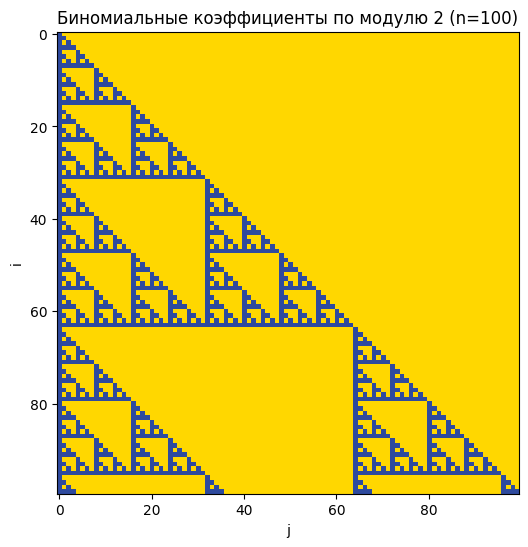

In [29]:
n = 100
# Матрица: M[i,j] = 1, если (i & j) == j, иначе 0
M = np.zeros((n, n), dtype=int)
for i in range(n):
    for j in range(i+1):          # j <= i
        if (i & j) == j:
            M[i, j] = 1

# Визуализация
cmap = ListedColormap(['#FFD700', '#2E4A9E'])  # жёлтый=0, синий=1
plt.figure(figsize=(6,6))
plt.imshow(M, cmap=cmap, interpolation='nearest')
plt.title("Биномиальные коэффициенты по модулю 2 (n=100)")
plt.xlabel("j"); plt.ylabel("i")
plt.show()

## Задача 1.12

Матрица Адамара $H_n$: элементы ±1, $H_n H_n^T = nI_n$, $H_0 \equiv 1$.

а) Выписать $H_1, H_2, H_4$.  
б) Показать $H_4 = H_2 \otimes H_2$.  
в)* Показать $H_{2^k} = H_2 \otimes H_{2^{k-1}}$.

### Теория
Конструкция Сильвестра:
$$
H_1 = (1),\quad
H_2 = \begin{pmatrix}1&1\\1&-1\end{pmatrix},\quad
H_{2n} = \begin{pmatrix}H_n & H_n\\ H_n & -H_n\end{pmatrix} = H_2 \otimes H_n.
$$
Это даёт матрицы Адамара для $n = 2^k$.

H1 =
 [[1]]

H2 =
 [[ 1  1]
 [ 1 -1]]

H4 =
 [[ 1  1  1  1]
 [ 1 -1  1 -1]
 [ 1  1 -1 -1]
 [ 1 -1 -1  1]]

H2 ⊗ H2 =
 [[ 1  1  1  1]
 [ 1 -1  1 -1]
 [ 1  1 -1 -1]
 [ 1 -1 -1  1]]
Совпадает с H4: True
H1 H1^T = 
[[1]]

H2 H2^T = 
[[2 0]
 [0 2]]

H4 H4^T = 
[[4 0 0 0]
 [0 4 0 0]
 [0 0 4 0]
 [0 0 0 4]]

Размер H64: (64, 64)


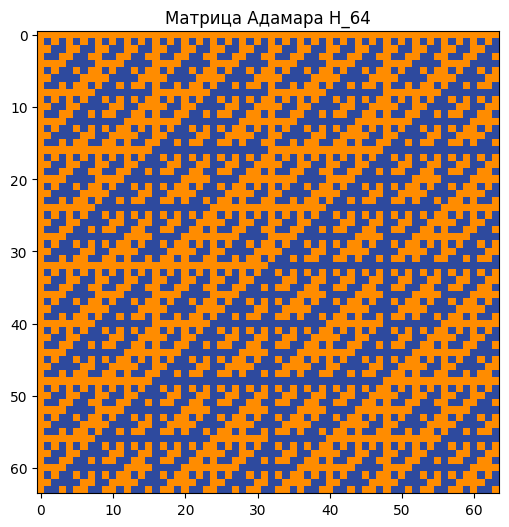

In [30]:
# H_1, H_2, H_4
H1 = np.array([[1]])
H2 = np.array([[1, 1],
               [1, -1]])
H4 = np.block([[H2,  H2],
               [H2, -H2]])

print("H1 =\n", H1)
print("\nH2 =\n", H2)
print("\nH4 =\n", H4)

# Проверка H4 = H2 ⊗ H2 (произведение Кронекера)
H4_kron = np.kron(H2, H2)
print("\nH2 ⊗ H2 =\n", H4_kron)
print("Совпадает с H4:", np.array_equal(H4, H4_kron))

# Проверка ортогональности: H_n H_n^T = n I
for n, H in [(1, H1), (2, H2), (4, H4)]:
    print(f"H{n} H{n}^T = \n{H @ H.T}\n")

# в) H_{2^k} = H2 ⊗ H_{2^{k-1}} — по индукции
# Построим H_64 и нарисуем
def hadamard(k):
    """Матрица Адамара порядка 2^k по конструкции Сильвестра."""
    H = np.array([[1]])
    for _ in range(k):
        H = np.block([[H,  H],
                      [H, -H]])
    return H

H64 = hadamard(6)
print("Размер H64:", H64.shape)

# Визуализация H64
cmap = ListedColormap(['#2E4A9E', '#FF8C00'])  # синий=-1, оранжевый=+1
plt.figure(figsize=(6,6))
plt.imshow(H64, cmap=cmap, interpolation='nearest')
plt.title("Матрица Адамара H_64")
plt.show()

## Задача 1.13

$$
A = \begin{pmatrix}14&10&21\\12&15&26\\18&11&27\end{pmatrix}.
$$
$Z$ — собственное значение с наибольшей мнимой частью.  
Найти: 1) $\operatorname{Im} Z$; 2) $\operatorname{Re} U$, где $X=(1,U,V)$ — собственный вектор, отвечающий $Z$.

### Теория
1. Собственные значения — корни характеристического многочлена $\det(A-\lambda I)=0$.
2. Для каждого $\lambda$ собственный вектор находится как решение $(A-\lambda I)X=0$.
3. Комплексные собственные значения вещественной матрицы идут **комплексно-сопряжёнными парами**.
4. Выбираем то $\lambda$, у которого $\operatorname{Im}$ максимальна (по модулю или по значению — смотрим по условию).
5. Нормируем собственный вектор так, чтобы первая координата была равна 1, и берём $\operatorname{Re} U$.

In [31]:
A = Matrix([[14, 10, 21],
            [12, 15, 26],
            [18, 11, 27]])

# 1) Характеристический многочлен
lam = symbols('lambda')
char_poly = A.charpoly(lam)
print("Характеристический многочлен:")
sp.pprint(char_poly.as_expr())

# 2) Собственные значения (символьно, точные)
eigenvals = A.eigenvals()
print("\nСобственные значения и их кратности:")
for val, mult in eigenvals.items():
    print(f"  {sp.nsimplify(val)}  (кратность {mult})")

# 3) Находим собственное значение с наибольшей мнимой частью
best = max(eigenvals.keys(), key=lambda v: im(v))
Z = sp.simplify(best)
print(f"\nZ (наибольшая мнимая часть) = {Z}")
print(f"Im(Z) = {im(Z)}")
print(f"Re(Z) = {re(Z)}")

# 4) Собственный вектор для Z
# Решаем (A - Z*I) X = 0
null_vecs = (A - Z*eye(3)).nullspace()
print(f"\nБазис собственного подпространства для Z:")
for v in null_vecs:
    sp.pprint(v)

# 5) Нормируем так, чтобы первая координата = 1
v = null_vecs[0]
U = sp.simplify(v[1] / v[0])
V = sp.simplify(v[2] / v[0])
X = Matrix([1, U, V])
print(f"\nX = (1, U, V) с U = {U}, V = {V}")
print(f"Re(U) = {sp.simplify(re(U))}")
print(f"Im(U) = {sp.simplify(im(U))}")

Характеристический многочлен:
 3       2              
λ  - 56⋅λ  + 209⋅λ - 208

Собственные значения и их кратности:
  2509/(9*(sqrt(249547)/3 + 125756/27)**(1/3)) + (sqrt(249547)/3 + 125756/27)**(1/3) + 56/3  (кратность 1)
  56/3 + 2509/(9*(-1/2 + sqrt(3)*I/2)*(sqrt(249547)/3 + 125756/27)**(1/3)) + (-1/2 + sqrt(3)*I/2)*(sqrt(249547)/3 + 125756/27)**(1/3)  (кратность 1)
  56/3 + (-1/2 - sqrt(3)*I/2)*(sqrt(249547)/3 + 125756/27)**(1/3) + 2509/(9*(-1/2 - sqrt(3)*I/2)*(sqrt(249547)/3 + 125756/27)**(1/3))  (кратность 1)

Z (наибольшая мнимая часть) = (-10036 + (1 - sqrt(3)*I)*(112 + (-1 + sqrt(3)*I)*(9*sqrt(249547) + 125756)**(1/3))*(9*sqrt(249547) + 125756)**(1/3))/(6*(1 - sqrt(3)*I)*(9*sqrt(249547) + 125756)**(1/3))
Im(Z) = -14*sqrt(3)/3 + sqrt(3)*(-10036 + (9*sqrt(249547) + 125756)**(1/3)*(2*(9*sqrt(249547) + 125756)**(1/3) + 112))/(24*(9*sqrt(249547) + 125756)**(1/3)) + sqrt(3)*(9*sqrt(249547) + 125756)**(1/3)/12
Re(Z) = (-10036 + (9*sqrt(249547) + 125756)**(1/3)*(2*(9*sqrt(249547) + 

## Задача 1.14


$$
A = \begin{pmatrix}
-3&7&-6&-1&8&-3&-2\\
1&-5&8&-3&-5&4&-5\\
1&3&-4&6&-2&0&8\\
-1&11&-12&9&3&-3&9\\
-3&11&-12&5&8&-4&6\\
-3&2&1&-4&4&1&-7\\
1&-5&6&-2&-4&3&-2
\end{pmatrix}.
$$

### Теория
- **Минимальный многочлен** $h(\lambda)$ — нормированный многочлен наименьшей степени с $h(A)=O$.
- Формула: $h(\lambda) = \dfrac{(-1)^n f(\lambda)}{d_{n-1}(\lambda)}$,
  где $f(\lambda) = \det(A-\lambda I)$, $d_{n-1}$ — НОД всех миноров $(n-1)$-го порядка характеристической матрицы $A-\lambda I$.
- Эквивалентно: $h(\lambda) = \prod_i (\lambda-\lambda_i)^{s_i}$,
  где $s_i$ — размер **наибольшей жордановой клетки** для $\lambda_i$.


In [5]:
A = Matrix([
    [-3,  7, -6, -1,  8, -3, -2],
    [ 1, -5,  8, -3, -5,  4, -5],
    [ 1,  3, -4,  6, -2,  0,  8],
    [-1, 11,-12,  9,  3, -3,  9],
    [-3, 11,-12,  5,  8, -4,  6],
    [-3,  2,  1, -4,  4,  1, -7],
    [ 1, -5,  6, -2, -4,  3, -2]
])

lam = symbols('lambda')
n = A.shape[0]

# --- Шаг 1. Характеристический многочлен ---
f = A.charpoly(lam).as_expr()
print("Характеристический многочлен f(λ):")
sp.pprint(sp.factor(f))

# --- Шаг 2. Спектр ---
eigenvals = A.eigenvals()
print("\nСпектр (собственные значения и их алгебраические кратности):")
for v, m in eigenvals.items():
    print(f"  λ = {v}, алг. кратность = {m}")

# --- Шаг 3. Минимальный многочлен через формулу НОД миноров ---
# Характеристическая матрица A - λI
M = A - lam * sp.eye(n)

# Все миноры (n-1)-го порядка: вычёркиваем i-ю строку и j-й столбец
minors = []
for i in range(n):
    for j in range(n):
        minor = M.minor_submatrix(i, j).det()
        minors.append(sp.expand(minor))

# НОД всех миноров (n-1)-го порядка
d = sp.gcd_list(minors)
d = sp.factor(d)
print("\nНОД всех миноров (n-1)-го порядка d(λ):")
sp.pprint(d)

# Минимальный многочлен
h = sp.factor(sp.cancel((-1)**n * f / d))
print("\nМинимальный многочлен h(λ) = (-1)^n · f(λ) / d(λ):")
sp.pprint(h)

# --- Шаг 4. Проверка: h(A) = O ---
# Преобразуем h(λ) в многочлен и подставим A
h_poly = sp.Poly(h, lam)
coeffs = h_poly.all_coeffs()          # от старшей степени к младшей

# Создаем нулевую матрицу того же размера, что и A
zero_matrix = sp.zeros(n, n)

# Суммируем, начиная с нулевой матрицы, чтобы тип был Matrix
h_A = sum((c * A**(len(coeffs)-1-k) for k, c in enumerate(coeffs)), zero_matrix)

print("\nПроверка: h(A) =")
sp.pprint(h_A)
print("Нулевая ли матрица?", h_A.is_zero_matrix)

# --- Шаг 5. Кросс-проверка через жорданову форму ---
print("\nЖорданова форма (для наглядности):")
P, J = A.jordan_form()
sp.pprint(J)
# Для каждого собственного λ смотрим максимальный размер клетки
from sympy import Matrix as _M
Jm = J.as_mutable()
# соберём размеры клеток
blocks = []
i = 0
while i < n:
    j = i
    while j+1 < n and Jm[j+1, j] == 1:
        j += 1
    blocks.append((Jm[i, i], j - i + 1))
    i = j + 1

# группируем по λ
from collections import defaultdict
sizes = defaultdict(int)
for val, size in blocks:
    sizes[val] = max(sizes[val], size)

print("\nСобственные значения → макс. размер жордановой клетки:")
for val, size in sizes.items():
    print(f"  λ = {val}, макс. размер клетки = {size}")

# Минимальный многочлен по Жордану
h_jordan = sp.prod((lam - val)**size for val, size in sizes.items())
print("\nh(λ) по Жордану =", sp.factor(h_jordan))
print("Совпадает с h(λ) по формуле НОД:", sp.simplify(h - sp.expand(h_jordan)) == 0)

Характеристический многочлен f(λ):
 3        4
λ ⋅(λ - 1) 

Спектр (собственные значения и их алгебраические кратности):
  λ = 1, алг. кратность = 4
  λ = 0, алг. кратность = 3

НОД всех миноров (n-1)-го порядка d(λ):
       2
(λ - 1) 

Минимальный многочлен h(λ) = (-1)^n · f(λ) / d(λ):
  3        2
-λ ⋅(λ - 1) 

Проверка: h(A) =
⎡0  0  0  0  0  0  0⎤
⎢                   ⎥
⎢0  0  0  0  0  0  0⎥
⎢                   ⎥
⎢0  0  0  0  0  0  0⎥
⎢                   ⎥
⎢0  0  0  0  0  0  0⎥
⎢                   ⎥
⎢0  0  0  0  0  0  0⎥
⎢                   ⎥
⎢0  0  0  0  0  0  0⎥
⎢                   ⎥
⎣0  0  0  0  0  0  0⎦
Нулевая ли матрица? True

Жорданова форма (для наглядности):
⎡0  1  0  0  0  0  0⎤
⎢                   ⎥
⎢0  0  1  0  0  0  0⎥
⎢                   ⎥
⎢0  0  0  0  0  0  0⎥
⎢                   ⎥
⎢0  0  0  1  1  0  0⎥
⎢                   ⎥
⎢0  0  0  0  1  0  0⎥
⎢                   ⎥
⎢0  0  0  0  0  1  1⎥
⎢                   ⎥
⎣0  0  0  0  0  0  1⎦

Собственные значения → макс. разме

## Задача 1.15

$$
A = \begin{pmatrix}17&-8&4\\-8&17&-4\\4&-4&11\end{pmatrix}.
$$

### Теория
Самосопряжённый оператор (симметричная матрица $A^T=A$):
1. Все собственные значения **вещественные**.
2. Собственные векторы, отвечающие различным λ, **ортогональны**.
3. Существует ортонормированный базис из собственных векторов, в котором $A$ диагональна: $A = C\Lambda C^T$, где $C$ — ортогональная матрица ($C^TC=I$).
4. Для кратных λ внутри собственного подпространства проводим **ортогонализацию Грама–Шмидта**, чтобы получить ортонормированный базис.

In [33]:
A = Matrix([[17, -8,  4],
            [-8, 17, -4],
            [ 4, -4, 11]])

# Проверка симметричности
assert A == A.T, "Матрица не симметрична!"
print("Матрица симметрична ✔")

# Собственные значения и векторы (символьно)
eigen_data = A.eigenvects()
print("\nСобственные значения и векторы:")
for val, mult, vecs in eigen_data:
    print(f"λ = {val}, кратность = {mult}")
    for v in vecs:
        sp.pprint(v)

# Собираем ортонормированный базис
basis = []
for val, mult, vecs in eigen_data:
    # Ортогонализация Грама–Шмидта внутри подпространства
    ortho = []
    for v in vecs:
        w = v
        for u in ortho:
            w = w - (w.dot(u) / u.dot(u)) * u
        ortho.append(sp.simplify(w))
    # Нормировка
    for u in ortho:
        basis.append(u / sp.sqrt(u.dot(u)))

C = Matrix.hstack(*basis)
print("\nМатрица перехода C (столбцы — собственные векторы):")
sp.pprint(C)

# Проверка ортогональности: C^T C = I
print("\nC^T · C =")
sp.pprint(sp.simplify(C.T * C))

# Диагонализация: C^T A C = diag(λ)
print("\nC^T · A · C =")
sp.pprint(sp.simplify(C.T * A * C))

Матрица симметрична ✔

Собственные значения и векторы:
λ = 9, кратность = 2
⎡1⎤
⎢ ⎥
⎢1⎥
⎢ ⎥
⎣0⎦
⎡-1/2⎤
⎢    ⎥
⎢ 0  ⎥
⎢    ⎥
⎣ 1  ⎦
λ = 27, кратность = 1
⎡2 ⎤
⎢  ⎥
⎢-2⎥
⎢  ⎥
⎣1 ⎦

Матрица перехода C (столбцы — собственные векторы):
⎡√2  -√2       ⎤
⎢──  ────  2/3 ⎥
⎢2    6        ⎥
⎢              ⎥
⎢√2   √2       ⎥
⎢──   ──   -2/3⎥
⎢2    6        ⎥
⎢              ⎥
⎢    2⋅√2      ⎥
⎢0   ────  1/3 ⎥
⎣     3        ⎦

C^T · C =
⎡1  0  0⎤
⎢       ⎥
⎢0  1  0⎥
⎢       ⎥
⎣0  0  1⎦

C^T · A · C =
⎡9  0  0 ⎤
⎢        ⎥
⎢0  9  0 ⎥
⎢        ⎥
⎣0  0  27⎦


## Задача 1.16

$$
f(x_1,x_2,x_3,x_4) = 3x_1^2 + 8x_1x_2 - 3x_2^2 + 4x_3^2 - 4x_3x_4 + x_4^2.
$$

### Теория
1. Записываем **симметричную матрицу** $A$ квадратичной формы:  
   $a_{ii}$ — коэффициенты при $x_i^2$,  
   $a_{ij} = a_{ji} = \tfrac12 \cdot$ (коэффициент при $x_ix_j$).
2. Находим собственные значения $\lambda_i$ и ортонормированные собственные векторы.
3. В базисе из собственных векторов форма принимает **канонический вид**:  
   $f = \lambda_1 y_1^2 + \lambda_2 y_2^2 + \lambda_3 y_3^2 + \lambda_4 y_4^2$.
4. Матрица перехода $C$ (столбцы — ортонормированные собственные векторы) — это и есть **ортогональное преобразование** к главным осям: $x = Cy$.

In [34]:
# Матрица квадратичной формы
A = Matrix([
    [3, 4, 0,  0],
    [4,-3, 0,  0],
    [0, 0, 4, -2],
    [0, 0,-2,  1]
])

print("Матрица квадратичной формы A:")
sp.pprint(A)
assert A == A.T
print("Симметрична ✔\n")

# Собственные значения и векторы
eigen_data = A.eigenvects()
print("Собственные значения:")
for val, mult, vecs in eigen_data:
    print(f"  λ = {val}, кратность = {mult}")

# Ортонормированный базис из собственных векторов
basis = []
for val, mult, vecs in eigen_data:
    ortho = []
    for v in vecs:
        w = v
        for u in ortho:
            w = w - (w.dot(u)/u.dot(u))*u
        ortho.append(sp.simplify(w))
    for u in ortho:
        basis.append(u / sp.sqrt(u.dot(u)))

C = Matrix.hstack(*basis)
print("\nОртогональная матрица C (столбцы — ортонорм. собств. векторы):")
sp.pprint(C)

print("\nПроверка C^T C = I:")
sp.pprint(sp.simplify(C.T * C))

print("\nC^T A C (диагональная матрица λ):")
sp.pprint(sp.simplify(C.T * A * C))

# Канонический вид
lams = [val for val, mult, _ in eigen_data for _ in range(mult)]
canonical = " + ".join(f"({l})·y{i+1}²" for i, l in enumerate(lams))
print(f"\nКанонический вид: f = {canonical}")# Матрица квадратичной формы
A = Matrix([
    [3, 4, 0,  0],
    [4,-3, 0,  0],
    [0, 0, 4, -2],
    [0, 0,-2,  1]
])

print("Матрица квадратичной формы A:")
sp.pprint(A)
assert A == A.T
print("Симметрична ✔\n")

# Собственные значения и векторы
eigen_data = A.eigenvects()
print("Собственные значения:")
for val, mult, vecs in eigen_data:
    print(f"  λ = {val}, кратность = {mult}")

# Ортонормированный базис из собственных векторов
basis = []
for val, mult, vecs in eigen_data:
    ortho = []
    for v in vecs:
        w = v
        for u in ortho:
            w = w - (w.dot(u)/u.dot(u))*u
        ortho.append(sp.simplify(w))
    for u in ortho:
        basis.append(u / sp.sqrt(u.dot(u)))

C = Matrix.hstack(*basis)
print("\nОртогональная матрица C (столбцы — ортонорм. собств. векторы):")
sp.pprint(C)

print("\nПроверка C^T C = I:")
sp.pprint(sp.simplify(C.T * C))

print("\nC^T A C (диагональная матрица λ):")
sp.pprint(sp.simplify(C.T * A * C))

# Канонический вид
lams = [val for val, mult, _ in eigen_data for _ in range(mult)]
canonical = " + ".join(f"({l})·y{i+1}²" for i, l in enumerate(lams))
print(f"\nКанонический вид: f = {canonical}")

Матрица квадратичной формы A:
⎡3  4   0   0 ⎤
⎢             ⎥
⎢4  -3  0   0 ⎥
⎢             ⎥
⎢0  0   4   -2⎥
⎢             ⎥
⎣0  0   -2  1 ⎦
Симметрична ✔

Собственные значения:
  λ = -5, кратность = 1
  λ = 0, кратность = 1
  λ = 5, кратность = 2

Ортогональная матрица C (столбцы — ортонорм. собств. векторы):
⎡-√5         2⋅√5        ⎤
⎢────   0    ────    0   ⎥
⎢ 5           5          ⎥
⎢                        ⎥
⎢2⋅√5         √5         ⎥
⎢────   0     ──     0   ⎥
⎢ 5           5          ⎥
⎢                        ⎥
⎢       √5         -2⋅√5 ⎥
⎢ 0     ──    0    ──────⎥
⎢       5            5   ⎥
⎢                        ⎥
⎢      2⋅√5          √5  ⎥
⎢ 0    ────   0      ──  ⎥
⎣       5            5   ⎦

Проверка C^T C = I:
⎡1  0  0  0⎤
⎢          ⎥
⎢0  1  0  0⎥
⎢          ⎥
⎢0  0  1  0⎥
⎢          ⎥
⎣0  0  0  1⎦

C^T A C (диагональная матрица λ):
⎡-5  0  0  0⎤
⎢           ⎥
⎢0   0  0  0⎥
⎢           ⎥
⎢0   0  5  0⎥
⎢           ⎥
⎣0   0  0  5⎦

Канонический вид: f = (-5)·y1² + (0)

## Задача 1.17

Определить тип кривой, её каноническое уравнение и каноническую систему координат:

**а)** $5x^2 + 4xy + 8y^2 - 32x - 56y + 80 = 0$  
**б)** $5x^2 + 12xy - 22x - 12y - 19 = 0$

### Теория
1. Выделяем квадратичную часть: матрица $A = \begin{pmatrix}a & b/2\\ b/2 & c\end{pmatrix}$ для $ax^2+bxy+cy^2$.
2. Собственные значения $\lambda_1, \lambda_2$:  
   - одного знака → **эллипс** (или точка/мнимый эллипс);  
   - разных знаков → **гипербола**;  
   - одно λ = 0 → **парабола**.
3. Поворотом (ортогонально) убираем $xy$; параллельным переносом убираем линейные члены.
4. Получаем каноническое уравнение и координаты центра/вершины.

In [35]:
x, y = symbols('x y', real=True)

def classify_conic(a, b, c, d, e, f, name):
    """
    ax² + bxy + cy² + dx + ey + f = 0
    b — коэффициент при xy (НЕ b/2).
    """
    print(f"\n===== {name} =====")
    A2 = Matrix([[a, Rational(b,2)],
                 [Rational(b,2), c]])
    print("Матрица квадратичной части:")
    sp.pprint(A2)

    # Собственные значения
    ev = A2.eigenvals()
    lams = sorted(ev.keys())
    print("Собственные значения:", lams)

    # Тип кривой
    l1, l2 = lams[0], lams[1]
    if l1 * l2 > 0:
        typ = "эллипс" if (d or e) else "точка/мнимый эллипс"
    elif l1 * l2 < 0:
        typ = "гипербола"
    else:
        typ = "парабола"
    print("Тип кривой:", typ)

    # Ортонормированный базис собственных векторов → угол поворота
    evecs = A2.eigenvects()
    basis = []
    for val, mult, vecs in evecs:
        for v in vecs:
            basis.append(v / sp.sqrt(v.dot(v)))
    C = Matrix.hstack(*basis)
    print("Матрица поворота C:")
    sp.pprint(C)

    # Центр: решаем A2 · (x0,y0)^T = -(d/2, e/2)^T
    center = A2.solve(Matrix([-Rational(d,2), -Rational(e,2)]))
    print("Центр (x0, y0):", center.T)

    # Свободный член после переноса
    F_new = f - (Matrix([Rational(d,2), Rational(e,2)]).T * center)[0]
    print(f"Свободный член после переноса: F = {F_new}")

    # Каноническое уравнение
    print(f"Каноническое уравнение: {l1}·X² + {l2}·Y² + {F_new} = 0")
    return lams, center, C

# --- а) ---
classify_conic(5, 4, 8, -32, -56, 80, "а) 5x² + 4xy + 8y² - 32x - 56y + 80 = 0")

# --- б) ---
classify_conic(5, 12, 0, -22, -12, -19, "б) 5x² + 12xy - 22x - 12y - 19 = 0")


===== а) 5x² + 4xy + 8y² - 32x - 56y + 80 = 0 =====
Матрица квадратичной части:
⎡5  2⎤
⎢    ⎥
⎣2  8⎦
Собственные значения: [4, 9]
Тип кривой: эллипс
Матрица поворота C:
⎡-2⋅√5    √5 ⎤
⎢──────   ── ⎥
⎢  5      5  ⎥
⎢            ⎥
⎢  √5    2⋅√5⎥
⎢  ──    ────⎥
⎣  5      5  ⎦
Центр (x0, y0): Matrix([[2, 3]])
Свободный член после переноса: F = 196
Каноническое уравнение: 4·X² + 9·Y² + 196 = 0

===== б) 5x² + 12xy - 22x - 12y - 19 = 0 =====
Матрица квадратичной части:
⎡5  6⎤
⎢    ⎥
⎣6  0⎦
Собственные значения: [-4, 9]
Тип кривой: гипербола
Матрица поворота C:
⎡-2⋅√13   3⋅√13⎤
⎢───────  ─────⎥
⎢  13      13  ⎥
⎢              ⎥
⎢ 3⋅√13   2⋅√13⎥
⎢ ─────   ─────⎥
⎣  13      13  ⎦
Центр (x0, y0): Matrix([[1, 1]])
Свободный член после переноса: F = -2
Каноническое уравнение: -4·X² + 9·Y² + -2 = 0


⎛              ⎡-2⋅√13   3⋅√13⎤⎞
⎜              ⎢───────  ─────⎥⎟
⎜         ⎡1⎤  ⎢  13      13  ⎥⎟
⎜[-4, 9], ⎢ ⎥, ⎢              ⎥⎟
⎜         ⎣1⎦  ⎢ 3⋅√13   2⋅√13⎥⎟
⎜              ⎢ ─────   ─────⎥⎟
⎝              ⎣  13      13  ⎦⎠

## Задача 1.18

$$
Q(x_1,x_2,x_3) = x_1^2 + 4x_2^2 + x_3^2 + 2\lambda x_1x_2 + 10x_1x_3 + 6x_2x_3.
$$

### Теория — критерий Сильвестра
Форма **положительно определена** ⇔ все **угловые миноры** матрицы $A$ положительны:
$$
\Delta_1 > 0,\quad \Delta_2 > 0,\quad \Delta_3 > 0.
$$
Составляем матрицу:
$$
A = \begin{pmatrix}
1 & \lambda & 5\\
\lambda & 4 & 3\\
5 & 3 & 1
\end{pmatrix}
$$
(коэффициент при $x_ix_j$ делим на 2 и ставим в позиции $(i,j)$ и $(j,i)$).

Далее находим условия на $\lambda$.

In [36]:
lam = symbols('lambda', real=True)
A = Matrix([
    [1,   lam, 5],
    [lam, 4,   3],
    [5,   3,   1]
])

# Угловые миноры
D1 = A[:1, :1].det()
D2 = A[:2, :2].det()
D3 = A.det()

print("Δ1 =", sp.factor(D1))
print("Δ2 =", sp.factor(D2))
print("Δ3 =", sp.factor(D3))

# Условия положительной определённости
conds = [D1 > 0, D2 > 0, D3 > 0]
print("\nУсловия:")
for c in conds:
    print(" ", sp.factor(c))

# Решаем систему неравенств
solution = sp.solve_univariate_inequality(D3 > 0, lam) if D3.has(lam) else None
print("\nD3 > 0  ⟺", sp.solve(D3 > 0, lam))
print("\nD2 > 0  ⟺", sp.solve(D2 > 0, lam))

# Итоговый интервал
intervals = sp.solve([D2 > 0, D3 > 0], lam, domain=sp.S.Reals)
print("\nОбщий ответ:", intervals)

Δ1 = 1
Δ2 = -(lambda - 2)*(lambda + 2)
Δ3 = -lambda**2 + 30*lambda - 105

Условия:
  True
  -(lambda - 2)*(lambda + 2) > 0
  -lambda**2 + 30*lambda - 105 > 0

D3 > 0  ⟺ (lambda < 2*sqrt(30) + 15) & (15 - 2*sqrt(30) < lambda)

D2 > 0  ⟺ (-2 < lambda) & (lambda < 2)

Общий ответ: False


## Задача 1.19

$$
Q(x_1,x_2,x_3) = \lambda x_1^2 - 2x_2^2 - 3x_3^2 + 2x_1x_2 - 2x_1x_3 + 2x_2x_3.
$$

### Теория — критерий Сильвестра (отрицательный)
Форма **отрицательно определена** ⇔ знаки угловых миноров чередуются, начиная с минуса:
$$
\Delta_1 < 0,\quad \Delta_2 > 0,\quad \Delta_3 < 0,\quad \dots,\quad (-1)^k \Delta_k > 0.
$$
Составляем матрицу:
$$
A = \begin{pmatrix}
\lambda & 1 & -1\\
1 & -2 & 1\\
-1 & 1 & -3
\end{pmatrix}
$$
(коэффициенты при $x_ix_j$ делим на 2).

In [37]:
lam = symbols('lambda', real=True)
A = Matrix([
    [lam, 1, -1],
    [1,  -2,  1],
    [-1,  1, -3]
])

D1 = A[:1, :1].det()
D2 = A[:2, :2].det()
D3 = A.det()

print("Δ1 =", sp.expand(D1))
print("Δ2 =", sp.expand(D2))
print("Δ3 =", sp.expand(D3))

# Отрицательная определённость: Δ1<0, Δ2>0, Δ3<0
conditions = [D1 < 0, D2 > 0, D3 < 0]
print("\nУсловия:")
for c in conditions:
    print(" ", c)

# Решаем
print("\nΔ1<0 ⟺ λ <", sp.solve(D1 < 0, lam))
print("Δ3<0 ⟺ λ ∈", sp.solve(D3 < 0, lam))
solution = sp.solve([D1 < 0, D3 < 0], lam, domain=sp.S.Reals)
print("\nОбщее решение:", solution)

Δ1 = lambda
Δ2 = -2*lambda - 1
Δ3 = 5*lambda + 3

Условия:
  lambda < 0
  -2*lambda - 1 > 0
  5*lambda + 3 < 0

Δ1<0 ⟺ λ < lambda < 0
Δ3<0 ⟺ λ ∈ lambda < -3/5

Общее решение: lambda < -3/5


## Задача 1.20

$$
Q_1 = 2x_1^2 + 9x_2^2 + 3x_3^2 + 8x_1x_2 - 4x_1x_3 - 10x_2x_3,
$$
$$
Q_2 = 2x_1^2 + 3x_2^2 + 6x_3^2 - 4x_1x_2 - 4x_1x_3 + 8x_2x_3.
$$

*(В файле в $Q_2$ опечатка: первое слагаемое $2x_1$ — читаем как $2x_1^2$.)*

### Теория — закон инерции
Две квадратичные формы **эквивалентны** над ℝ ⇔ у них **одинаковая сигнатура** $(p, q)$:
- $p$ — число положительных собственных значений матрицы формы,
- $q$ — число отрицательных,
- ранг $r = p + q$.

Приводим обе к диагональному виду, сравниваем сигнатуры.

In [39]:
Q1 = Matrix([
    [2,  4, -2],
    [4,  9, -5],
    [-2,-5,  3]
])
Q2 = Matrix([
    [ 2, -2, -2],
    [-2,  3,  4],
    [-2,  4,  6]
])

print("Матрица Q1:")
sp.pprint(Q1)
print("\nМатрица Q2:")
sp.pprint(Q2)

# Собственные значения
ev1 = Q1.eigenvals()
ev2 = Q2.eigenvals()
print("\nСобственные значения Q1:", ev1)
print("Собственные значения Q2:", ev2)

def signature(M):
    """Возвращает (p, q, r) — число положительных, отрицательных и ранг."""
    evs = M.eigenvals()
    vals = []
    for v, m in evs.items():
        vals += [v] * m
    p = sum(1 for v in vals if v > 0)
    q = sum(1 for v in vals if v < 0)
    z = sum(1 for v in vals if v == 0)
    return p, q, p + q

p1, q1, r1 = signature(Q1)
p2, q2, r2 = signature(Q2)
print(f"\nСигнатура Q1: p={p1}, q={q1}, ранг={r1}")
print(f"Сигнатура Q2: p={p2}, q={q2}, ранг={r2}")

if (p1, q1) == (p2, q2):
    print("\nФормы ЭКВИВАЛЕНТНЫ (одинаковая сигнатура)")
else:
    print("\nФормы НЕ эквивалентны")

# Для наглядности — канонический вид
print("\nКанонический вид Q1:")
print("  ", " + ".join(f"({v})·y{i+1}²" for i, v in enumerate(sorted(ev1.keys()))))
print("Канонический вид Q2:")
print("  ", " + ".join(f"({v})·y{i+1}²" for i, v in enumerate(sorted(ev2.keys()))))

Матрица Q1:
⎡2   4   -2⎤
⎢          ⎥
⎢4   9   -5⎥
⎢          ⎥
⎣-2  -5  3 ⎦

Матрица Q2:
⎡2   -2  -2⎤
⎢          ⎥
⎢-2  3   4 ⎥
⎢          ⎥
⎣-2  4   6 ⎦

Собственные значения Q1: {7 - sqrt(43): 1, sqrt(43) + 7: 1, 0: 1}
Собственные значения Q2: {11/2 - sqrt(73)/2: 1, sqrt(73)/2 + 11/2: 1, 0: 1}

Сигнатура Q1: p=2, q=0, ранг=2
Сигнатура Q2: p=2, q=0, ранг=2

Формы ЭКВИВАЛЕНТНЫ (одинаковая сигнатура)

Канонический вид Q1:
   (0)·y1² + (7 - sqrt(43))·y2² + (sqrt(43) + 7)·y3²
Канонический вид Q2:
   (0)·y1² + (11/2 - sqrt(73)/2)·y2² + (sqrt(73)/2 + 11/2)·y3²
